# Öğrenci Değerlendirme Verisi İnceleme

.xlsx dosyasına kayıtlı öğrenci isim, grup, puan ve not değerlendirmelerinin yine aynı dosyadaki maddelere göre analizi aşağıdaki gibidir.

Python'da .xlsx uzantılı bir Excel dosyasının farklı sayfalarına (sheet) erişmek için pandas kütüphanesi ve openpyxl kullanıldı. Excel dosyasındaki okunması istenen sayfanın gelmesi için sayfanın tam adı sheet_name parametresine sayfa adını string olarak ya da indeks numarası integer olarak yazılabilir. 

In [67]:
import pandas as pd
import openpyxl as px
df = pd.read_excel('degerlendirme_veri.xlsx', sheet_name=1)
print(df.head())

   No        Ad Soyad Grup
0   1  Ahmet Yıldırım    A
1   2    Mehmet Demir    B
2   3       Ayşe Kaya    C
3   4     Fatma Şahin    A
4   5    Hasan Arslan    B


## Öğrencilerin Gruplara Göre Listelenmesi

In [68]:
#Öğrencilerin gruplara bölünmüş listesi

grup_listesi = df.groupby('Grup')['Ad Soyad'].apply(list)
print(grup_listesi)

Grup
A    [Ahmet Yıldırım, Fatma Şahin, Zeynep Aydın, Mu...
B    [Mehmet Demir, Hasan Arslan, Emre Korkmaz, Ali...
C    [Ayşe Kaya, Hüseyin Yalçın, Elif Çetin, Hakan ...
Name: Ad Soyad, dtype: object


1. Öğrencilerin Gruplara Dağılımı

In [69]:
#Öğrencilerin gruplara dağılımı

dagilim = df['Grup'].value_counts()
print(dagilim)

Grup
A    17
B    17
C    16
Name: count, dtype: int64


2. Sınav ve Değerlendirme Verilerinin Normalize Edilmesi

Öncelikle öğrencilerin numaralarına göre sıralanmış sınav notlarının olduğu .xlsx sayfası getirilmiştir. Daha sonra notların minimum ve maksimum değerleri bulunup sistemde ayrı olarak verilmiş normalize etme formulü ile sınav notları normalize edilmiştir. 

In [ ]:
#Normalize edilmiş sınav notları
# Excel dosyasını okuma
df1 = pd.read_excel("degerlendirme_veri.xlsx", sheet_name=2)

# Min-Max Normalizü (0 - 1 arasına dönüştürme)
min_not = df1['Not'].min()
max_not = df1['Not'].max()

# Bölme hatası almamak için kontrol
if max_not != min_not:
    df1['Normalize_Not'] = (df1['Not'] - min_not) / (max_not - min_not)
else:
    df1['Normalize_Not'] = 0.0

# Yeni eklenen normalize sütununu görmek için
print(df1[['No', 'Not', 'Normalize_Not']].head(10))

   No     Not  Normalize_Not
0   1   50.00         0.5000
1   2  100.00         1.0000
2   3  100.00         1.0000
3   4  100.00         1.0000
4   5  100.00         1.0000
5   6  100.00         1.0000
6   7  100.00         1.0000
7   8  100.00         1.0000
8   9    0.00         0.0000
9  10   16.67         0.1667


Sınav notlarına uygulanan normalize etme süreci aynı şekilde .xlsx dosyasında 3. indekste bulunan günlük değerlendirme puanlarına da uygulanmıştır. Puanların öncelikle minimum ve maksimum değerleri alınıp daha sonra sistemdeki normalize etme formulüne göre normalizasyon uygulanmıştır.

In [76]:
#Normalize edilmiş günlük değerlendirme notları

# Excel dosyasını okuma
df2 = pd.read_excel("degerlendirme_veri.xlsx", sheet_name=3)

# Min-Max Normalizü (0 - 1 arasına dönüştürme)
min_puan = df2['Puan'].min()
max_puan = df2['Puan'].max()

# Bölme hatası almamak için kontrol
if max_puan != min_puan:
    df2['Normalize_Puan'] = (df2['Puan'] - min_puan) / (max_puan - min_puan)
else:
    df2['Normalize_Puan'] = 0

# Yeni eklenen normalize sütununu görmek için
print(df2[['No', 'Puan', 'Normalize_Puan']].head(10))

   No  Puan  Normalize_Puan
0   1     3        0.333333
1   2     6        0.666667
2   3     6        0.666667
3   4     6        0.666667
4   5     6        0.666667
5   6     6        0.666667
6   7     6        0.666667
7   8     6        0.666667
8   9     0        0.000000
9  10     1        0.111111


3. Kişinin başarı ölçüsü belirlenmesi

Sınav başarı ve Değerlendirme verilerini kullanan bir ölçü belirleyip ( normalize değerleri kullanarak) (Normalize_Not * 0.7 + Normalize_Puan * 0,3) formülünü kullanarak öğrenci numarasına göre kişinin başarı ölçüsü listelenmiştir. Bunun için yeni bir DataFrame oluşturularak tablo görünümü sağlanmıştır.

In [77]:
# (Normalize Not * 0.7 + Normalize Puan * 0.3)
basari_df = (df1['Normalize_Not'] * 0.7) + (df2['Normalize_Puan'] * 0.3)
yeni_df = pd.DataFrame({'Tarih' : df1['Tarih'], 'No' : df1['No'], 'Basari_Olcusu' : basari_df})
print(yeni_df.head(10))

       Tarih  No  Basari_Olcusu
0 2022-10-10   1       0.450000
1 2022-10-10   2       0.900000
2 2022-10-10   3       0.900000
3 2022-10-10   4       0.900000
4 2022-10-10   5       0.900000
5 2022-10-10   6       0.900000
6 2022-10-10   7       0.900000
7 2022-10-10   8       0.900000
8 2022-10-10   9       0.000000
9 2022-10-10  10       0.150023


4. Başarı ölçüsünü kullanarak en başarılı N öğrenci

Bu kısımdan sonra başarı ölçüsü belirlenmiş öğrencileri tüm tarihler üzerinden istediği için .xlsx dosyasındaki mevcut dosyaların birleşmesi gerekiyordu. Bu nedenle öncelikle .xlsx dosyasının mevcut sayfaları birleştirilmiştir. Bundan sonraki işlemler df_birleşik adıyla tanımlanmış birleştirilmiş sayfalarla sağlanmıştır. 

Tüm veriler Tarih ve No sütunları üzerinden birleştirilmiştir. Günlük sınav ve değerlendirmeler tarihlere göre birden fazla satır tuttuğu için hem No hem Tarih sütunları üzerinden birleştirme işlemi yapılmıştır.

In [ ]:
import pandas as pd

dosya_yolu = "degerlendirme_veri.xlsx"

# Sayfaları okuma
df_ogrenci = pd.read_excel(dosya_yolu, sheet_name="Ogrenciler")
df_sinav = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Sinav")
df_degerlendirme = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Degerlendirme")

# Tüm verileri 'No' ve 'Tarih' üzerinden birleştirme
# Not: Günlük sınav ve değerlendirmeler tarihlere göre birden fazla satır tutuyorsa 'No' ve 'Tarih' üzerinden merge edilir.
df_birlesik = pd.merge(df_sinav, df_degerlendirme, on=['Tarih', 'No'])
df_birlesik = pd.merge(df_birlesik, df_ogrenci, on='No')
df_birlesik = pd.merge(df_birlesik, yeni_df, on=['Tarih', 'No'])

Birleştirme işleminden sonra df_birleşik adıyla tanımlanmış yeni sayfada en yüksek başarı ölçüsüne sahip N sayıda kişiyi sıralaması için .sort_values() parametresi kullanılmıştır. N sayısına 5 rakamı atanarak en_basarili_n olarak tanımlanmış tablo tarih bilgisi de dahil edilerek yazdırılmıştır.

In [ ]:
N = 5 

# Tüm tarihler/satırlar içinde en yüksek başarı ölçüsüne sahip ilk N kişi
en_basarili_n = df_birlesik.sort_values(by='Basari_Olcusu', ascending=False).head(N)

print(f"--- En Başarılı İlk {N} Öğrenci ---")
print(en_basarili_n[['Tarih', 'No', 'Ad Soyad', 'Basari_Olcusu']])

--- En Başarılı İlk 5 Öğrenci ---
         Tarih  No        Ad Soyad  Basari_Olcusu
233 2022-10-14  34   Orhan Efeoğlu            1.0
231 2022-10-14  32  Burak Demirtaş            1.0
240 2022-10-14  41   Ayhan Kocaman            1.0
201 2022-10-14   2    Mehmet Demir            1.0
218 2022-10-14  19       Kemal Taş            1.0


5. Başarı ölçüsünü kullanarak en başarılı grup

Yukarıda N sayıda öğrenci için uygulanan başarı ölçüsü kullanılarak yapılan sıralama aynı şekilde gruplar üzerinden hesaplanmıştır. 
"grup_basari" adıyla tanımlanmış, "Grup" kolonuna göre gruplanmış öğrencilerin başarı ölçüsünün ortalaması alınarak grubuna göre sonuçlar yazdırılmıştır. 

In [ ]:
# Grupların ortalama başarı ölçüsünü hesaplama
grup_basari = df_birlesik.groupby('Grup')['Basari_Olcusu'].mean().reset_index()

# En yüksek ortalamaya sahip grubu bulma
en_basarili_grup = grup_basari.loc[grup_basari['Basari_Olcusu'].idxmax()]

print("--- Grupların Başarı Ortalamaları ---")
print(grup_basari)
print(f"\nEn Başarılı Grup: {en_basarili_grup['Grup']} (Ortalama: {en_basarili_grup['Basari_Olcusu']:.4f})")

--- Grupların Başarı Ortalamaları ---
  Grup  Basari_Olcusu
0    A       0.654059
1    B       0.674344
2    C       0.638168

En Başarılı Grup: B (Ortalama: 0.6743)


6. Grupların verili tarih aralığında başarı grafiği

Grupların verili tarih aralığına göre bir başarı grafiği istendiğinden dolayı öncelikle öğrencilerin başarı ölçüsü "Grup" ve "Tarih" kolonlarına göre gruplanmıştır. 
Daha sonrasında çeşidi çizgi grafiği olan, 10'a 5' ölçülerde, x ekseninde "Tarih, y ekseninde "Ortalama Başarı Ölçüsü"nün bulunduğu, .legend ile sağ üst köşeye ilgili gruprın adının ve atanın renginin yazılı olduğu grafik oluşturulmuştur.

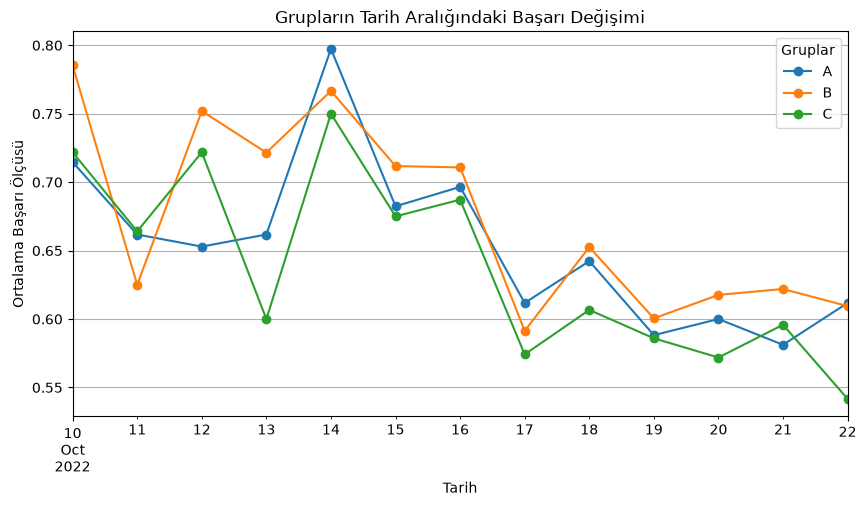

In [ ]:
import matplotlib.pyplot as plt

# Tarihe ve gruba göre ortalama başarı ölçüsü
grup_zaman = df_birlesik.groupby(['Tarih', 'Grup'])['Basari_Olcusu'].mean().unstack()

# Çizgi grafiği çizdirme
grup_zaman.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Grupların Tarih Aralığındaki Başarı Değişimi')
plt.xlabel('Tarih')
plt.ylabel('Ortalama Başarı Ölçüsü')
plt.grid(True)
plt.legend(title='Gruplar')
plt.show()

7. Günlük Sınav Ortalamasının değişimi grafiği

Günlük sınav ortalamasının değişiminin ölçümünü sağlayabilmek için grafikte tarih aralığına göre not ortalamalarının görüntüsünün bulunması gerekir. Bu nedenle öncelikle Not ortalamaları "Tarih" sütununa göre gruplandırılarak bir tablo tanımlanır. 
Daha sonra türü sütun grafiği olan, sütun rengi mavi, 8'e 4 ölçülerde, x ekseninde "Tarih", y ekseninde sınav notlarının ortalamalarının sıralı olduğu sütun grafiği çizdirilmiştir.

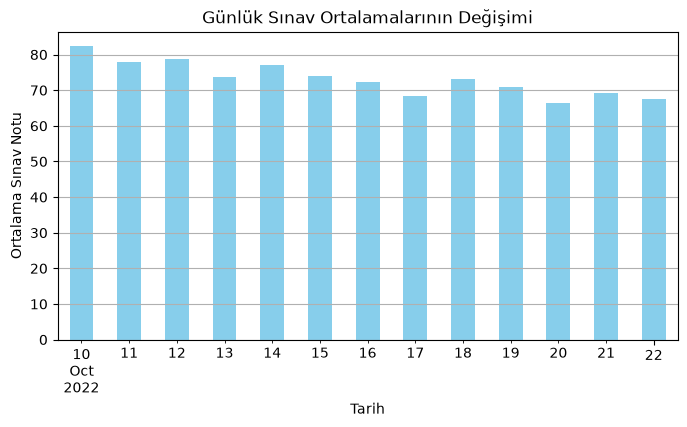

In [ ]:
# Tarihlere göre sınıfın sınav notu ortalaması
gunluk_ortalama = df_birlesik.groupby('Tarih')['Not'].mean()

# Grafiğe dökme
gunluk_ortalama.plot(kind='bar', color='skyblue', figsize=(8, 4))
plt.title('Günlük Sınav Ortalamalarının Değişimi')
plt.xlabel('Tarih')
plt.ylabel('Ortalama Sınav Notu')
plt.grid(axis='y')
plt.show()

8. Öğrenciler, Sınav Notu ve Değerlendirme verilerinin Tanımlayıcı İstatistiği

Öncelikle tanımlayıcı istatistik istendiğinden dolayı .describe() kodlaması ile birleştirilmiş tablonun tanımlayıcı istetistiği yazdırılmıştır. Ancak Ortalama, Medyan, Mod, Standart sapma değerleri bulunup görselleştirmesi istendiği için .describe() parametresinin istenilenleri tek başına cevap verememesi ihtimaline karşılık, istenilenlere göre uzun bir kodlama da aşağıda verilmiştir.

In [ ]:
df_birlesik.describe()

,Tarih,No,Not,Puan,Basari_Olcusu
count,650,650.000000,650.000000,650.000000,650.000000
mean,2022-10-16 00:00:00,25.500000,73.212323,4.301538,0.655871
min,2022-10-10 00:00:00,1.000000,0.000000,0.000000,0.000000
25%,2022-10-13 00:00:00,13.000000,50.000000,3.000000,0.450000
50%,2022-10-16 00:00:00,25.500000,100.000000,5.000000,0.866667
75%,2022-10-19 00:00:00,38.000000,100.000000,6.000000,0.900000
max,2022-10-22 00:00:00,50.000000,100.000000,9.000000,1.000000
std,NaN,14.441983,39.873394,2.628778,0.359301


İstenilenlere göre df_birleşik tablosunun tanımlayıcı istatistiği oluşturulmuş ve index olarak ortalama, medyan, mod ve standart sapma satırları atanarak istenen tablo yazdırılmıştır. 
Görselde ise tablolarda Not 100, Puan 10 üzerinden değerlendirildiği için sadece "Not" ve "Puan" sütunlarının kutu grafiğinde dengesiz bir görüntü oluşturacağı için kutu grafiğinde kullanılacak verinin (data=) "Normalize_Not" ve "Normalize_Puan" olmasına dikkat edilmiştir. 
8'e 5 boyutlarında oluşturulmuş kutu grafiği aşağıdaki gibi yazdırılmıştır.

--- Tanımlayıcı İstatistikler ---
                       Not      Puan  Basari_Olcusu
Ortalama         73.212323  4.301538       0.655871
Medyan          100.000000  5.000000       0.866667
Mod             100.000000  5.000000       0.000000
Standart Sapma   39.873394  2.628778       0.359301


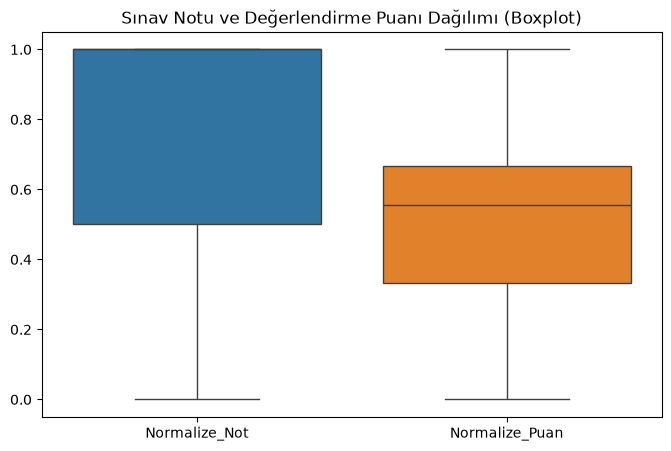

In [ ]:
# Ortalama, Medyan, Mod, Standart Sapma değerleri
tanimlayici_istatistik = df_birlesik[['Not', 'Puan', 'Basari_Olcusu']].agg(['mean', 'median', lambda x: x.mode().iloc[0], 'std'])
tanimlayici_istatistik.index = ['Ortalama', 'Medyan', 'Mod', 'Standart Sapma']

print("--- Tanımlayıcı İstatistikler ---")
print(tanimlayici_istatistik)

# Görselleştirme (Boxplot ile dağılımı inceleme)
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.boxplot(data=[df1['Normalize_Not'], df2['Normalize_Puan']])
plt.title('Sınav Notu ve Değerlendirme Puanı Dağılımı (Boxplot)')
plt.show()

9. Öğrenci gruplarına göre pasta grafiğinde başarı ölçüsünün görüntüsü nasıldır?

Veri ile ilgili bir soruyu yanıtlamamız istendiği için yukarıda belirlenen soruya göre aşağıda başarı ölçüsünün ortalamalarının "Grup" sütununa göre gruplanmış listesi tanımlanmıştır. Daha sonrasında 7'ye 7 ölçüde, türü pasta grafiği olan, yüzdelik dilimlerin yazdırıldığı (autopct='%1.1f%%') grafik yazdırılmıştır.

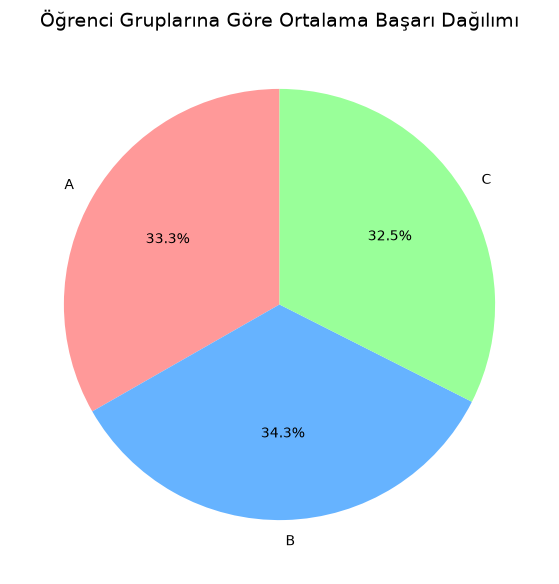

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Gruplara göre ortalama başarı ölçüsünü hesaplama
grup_basari = df_birlesik.groupby('Grup')['Basari_Olcusu'].mean()

# 2. Pasta grafiğini oluşturma
plt.figure(figsize=(7, 7))

grup_basari.plot(
    kind='pie', 
    autopct='%1.1f%%',   # Yüzdelik dilimleri dilimlerin üzerine yazdırma
    startangle=90,       # Grafiği 90 dereceden başlatma
    colors=['#ff9999','#66b3ff','#99ff99'] # Renk özelleştirmesi
)

plt.title('Öğrenci Gruplarına Göre Ortalama Başarı Dağılımı', fontsize=14)
plt.ylabel('') # Y ekseni etiketini temizleme

# Grafiği ekranda gösterme
plt.show()

10. Grupların normalize not ortalaması ve normalize puan ortalaması karşılaştırması nasıldır?

İkinci veri ile ilgili bir soruyu yanıtlama göreviyle ilgili olarak yazılmış bu soruda normalize nor ve normalize puan karşılaştırmaları istenmektedir. Yukarıda kodlamada kolaylık sağlaması için birleştirme yapılmış df_birleşik tanımına "Normalize_Not" ve "Normalize_Puan" bilgileri eklenmediği için öncelikle bu işlem gerçekleştirilmiştir. min_not ve max_not olarak tanımlanmış öğrenci notlarının minimum ve maksimum değerleri belirlenip, verili formülle normalizasyon işlemi sağlanmış ve aynı işlem min_puan ve max_puan tanımları ile öğrenci puanlarına da uygulanmıştır. 
Elde edilen normalize edilmiş not ve puan bilgileri df_birleşik diye tanımlanan bütünleştirilmiş sayfaya eklenmiştir.

In [ ]:
# Min-Max Normalizasyonu (0 - 1 arası)
# Sınav Notu (0-100 arası)
min_not, max_not = df_birlesik['Not'].min(), df_birlesik['Not'].max()
df_birlesik['Normalize_Not'] = (df_birlesik['Not'] - min_not) / (max_not - min_not)

# Değerlendirme Puanı (0-10 arası)
min_puan, max_puan = df_birlesik['Puan'].min(), df_birlesik['Puan'].max()
df_birlesik['Normalize_Puan'] = (df_birlesik['Puan'] - min_puan) / (max_puan - min_puan)

print(df_birlesik[['Tarih', 'No', 'Not', 'Normalize_Not', 'Puan', 'Normalize_Puan']].head())

       Tarih  No    Not  Normalize_Not  Puan  Normalize_Puan
0 2022-10-10   1   50.0            0.5     3        0.333333
1 2022-10-10   2  100.0            1.0     6        0.666667
2 2022-10-10   3  100.0            1.0     6        0.666667
3 2022-10-10   4  100.0            1.0     6        0.666667
4 2022-10-10   5  100.0            1.0     6        0.666667


Normalize not ve puan bir tabloya geçirildikten sonra soruda istendiği şekilde normalize not ve puanların öğrenci gruplarına göre oluşturulmuş karşılaştırmasını veren sütun grafiği oluşturulmuştur. 
Bunun için öncelikle Normalize_Not ve Normalize_Puan sütunlarının ortalamalarının öğrenci gruplarına göre gruplandırıldığı grup_karsilastirma tanımı oluşturulmuştur.
9'a 5 ölçüde türü karşılaştırmalı sütun grafiği olan (subplots) grafik yazdırılmıştır.

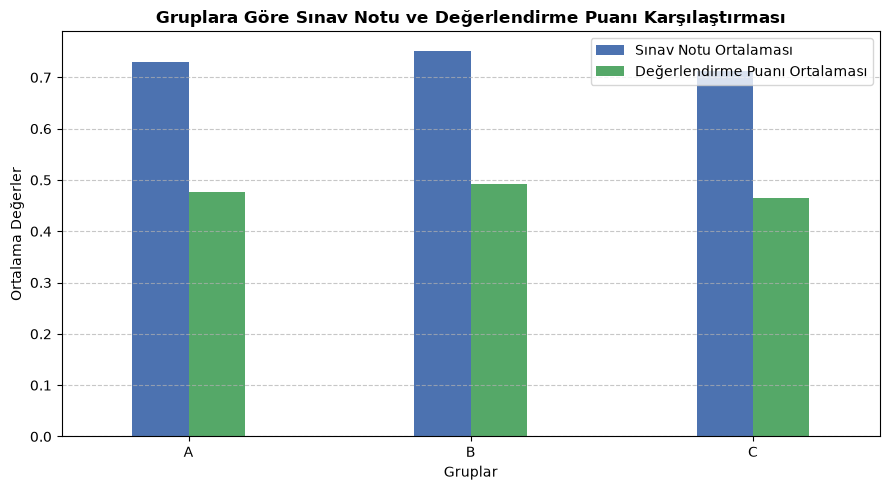

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Gruplara göre Sınav Notu ve Değerlendirme Puanının ortalamasını hesaplama
grup_karsilastirma = df_birlesik.groupby('Grup')[['Normalize_Not', 'Normalize_Puan']].mean()

# 2. Karşılaştırmalı Sütun Grafiği Çizme
fig, ax = plt.subplots(figsize=(9, 5))

# İki sütunu (Not ve Puan) yan yana çubuklar olarak çizdirme
grup_karsilastirma.plot(kind='bar', ax=ax, width=0.4, color=['#4C72B0', '#55A868'])

plt.title('Gruplara Göre Sınav Notu ve Değerlendirme Puanı Karşılaştırması', fontsize=12, fontweight='bold')
plt.xlabel('Gruplar', fontsize=10)
plt.ylabel('Ortalama Değerler', fontsize=10)

# Eksen ve etiket düzenlemeleri
plt.xticks(rotation=0)  # Grup adlarını düz tutma
plt.legend(['Sınav Notu Ortalaması', 'Değerlendirme Puanı Ortalaması'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Grafiği ekranda gösterme
plt.tight_layout()
plt.show()